# Cookie Cats A/B 테스트 — 게이트 위치 변경이 유저 유지율에 미치는 영향

**작성자**: 조익현  
**목적**: 게이트를 레벨 30 → 40으로 옮겼을 때 유지율이 달라지는지 검증하고, 의사결정과 액션 아이템을 도출한다.

**분석 흐름**
1. 실험 설계 (가설, 지표, 표본 크기)
2. 데이터 점검 (결측, 중복, SRM, 이상치)
3. A/B 검정 (빈도주의 + 베이지안)
4. 세그먼트 Deep Dive (어떤 유저에게서 차이가 나는가)
5. 결론, 액션 아이템, 한계점

**데이터 컬럼**
| 컬럼 | 의미 |
|---|---|
| userid | 유저 ID |
| version | gate_30(기존) / gate_40(변경) |
| sum_gamerounds | 설치 후 14일 동안 플레이한 라운드 수 |
| retention_1 | 설치 1일 뒤 재접속 여부 |
| retention_7 | 설치 7일 뒤 재접속 여부 |

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint, proportion_effectsize
from statsmodels.stats.power import NormalIndPower

# 한글 폰트 (Windows: Malgun Gothic)
for f in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]:
    if any(f == x.name for x in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = f
        break
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110

RNG = np.random.default_rng(42)
ALPHA = 0.05

if Path("cookie_cats.csv").exists():
    df = pd.read_csv("cookie_cats.csv")
elif Path("cookie_cats.xlsx").exists():
    df = pd.read_excel("cookie_cats.xlsx")
else:
    raise FileNotFoundError("노트북과 같은 폴더에 cookie_cats.csv (또는 .xlsx) 파일이 필요합니다.")

df[["retention_1", "retention_7"]] = df[["retention_1", "retention_7"]].astype(int)
print(df.shape)
df.head()

(90189, 5)


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,0,0
1,337,gate_30,38,1,0
2,377,gate_40,165,1,0
3,483,gate_40,1,0,0
4,488,gate_40,179,1,1


## 1. 실험 설계

### 배경
모바일 퍼즐 게임 Cookie Cats는 일정 레벨마다 **게이트**가 나온다. 유저는 일정 시간을 기다리거나 결제해야 다음 레벨로 갈 수 있다.
게이트는 수익과 피로감을 동시에 만드는 장치라서, 위치가 유지율(장기적으로 매출의 기반)에 영향을 줄 수 있다.
이 실험은 게이트를 **레벨 30(gate_30, 기존) → 레벨 40(gate_40, 변경)** 으로 옮겼을 때 유지율이 달라지는지 확인한다.

### 가설
- **H0**: gate_30과 gate_40의 유지율은 같다.
- **H1**: 두 그룹의 유지율이 다르다. (양측 검정. 게이트를 늦추면 좋아질 수도, 몰입이 끊겨 나빠질 수도 있어 방향을 열어둔다.)

### 지표 정의
| 구분 | 지표 | 정의 | 선정 이유 |
|---|---|---|---|
| 주 지표 | retention_1 | 설치 1일 뒤 재접속 비율 | 초기 경험 품질 |
| 주 지표 | retention_7 | 설치 7일 뒤 재접속 비율 | 게이트(30~40레벨)를 만나는 시점과 가까워 효과가 나타날 지표 |
| 가드레일(보조) | sum_gamerounds | 14일 누적 라운드 수 | 참여도가 크게 떨어지지 않는지 확인 |

> 이 데이터에는 결제/매출 컬럼이 없다. 게이트의 수익 측면은 평가할 수 없다는 점을 한계점에 기록한다.

### 유의수준
- 주 지표가 2개이므로 **Bonferroni 보정**을 적용한다. 개별 검정 기준은 α = 0.05 / 2 = 0.025.
- 검정력 80%, 양측 검정.

In [2]:
# 표본 크기 / 검정력 계산 (retention_7 기준)
base7 = df["retention_7"].mean()
alpha_adj = ALPHA / 2
power = 0.8

# (1) 절대 1%p 차이를 탐지하려면 그룹당 몇 명이 필요한가
mde = 0.01
es = proportion_effectsize(base7, base7 - mde)
n_req = NormalIndPower().solve_power(effect_size=es, alpha=alpha_adj, power=power, ratio=1, alternative="two-sided")

# (2) 실제 그룹 크기로 탐지 가능한 최소 차이(MDE)는 얼마인가
n_min = df["version"].value_counts().min()
es_min = NormalIndPower().solve_power(nobs1=n_min, alpha=alpha_adj, power=power, ratio=1, alternative="two-sided")
p2 = np.sin(np.arcsin(np.sqrt(base7)) - es_min / 2) ** 2
mde_actual = base7 - p2

print(f"기준 7일 유지율: {base7:.2%}")
print(f"1%p 차이를 탐지하는 데 필요한 표본: 그룹당 약 {int(np.ceil(n_req)):,}명")
print(f"실제 최소 그룹 크기: {n_min:,}명 → 탐지 가능한 최소 차이(MDE) 약 {mde_actual*100:.2f}%p")
print("→ 표본이 충분하므로 1%p 안팎의 작은 차이도 검정할 수 있다." if n_min >= n_req else "→ 표본이 부족할 수 있어 해석에 주의가 필요하다.")

기준 7일 유지율: 18.61%
1%p 차이를 탐지하는 데 필요한 표본: 그룹당 약 28,184명
실제 최소 그룹 크기: 44,700명 → 탐지 가능한 최소 차이(MDE) 약 0.80%p
→ 표본이 충분하므로 1%p 안팎의 작은 차이도 검정할 수 있다.


## 2. 데이터 점검
점검 항목
- 결측치, 중복 유저
- 그룹 배정 비율(SRM, Sample Ratio Mismatch): 50:50 배정인데 비율이 어긋나면 실험 설계나 로깅에 문제가 있을 수 있다.
- `sum_gamerounds` 이상치

In [3]:
df.info()
print()
print("결측치\n", df.isna().sum(), sep="")
print("\nuserid 중복 수:", df["userid"].duplicated().sum())
print("\n그룹별 인원\n", df["version"].value_counts(), sep="")

<class 'pandas.DataFrame'>
RangeIndex: 90189 entries, 0 to 90188
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   userid          90189 non-null  int64
 1   version         90189 non-null  str  
 2   sum_gamerounds  90189 non-null  int64
 3   retention_1     90189 non-null  int64
 4   retention_7     90189 non-null  int64
dtypes: int64(4), str(1)
memory usage: 3.4 MB

결측치
userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64

userid 중복 수: 0

그룹별 인원
version
gate_40    45489
gate_30    44700
Name: count, dtype: int64


In [4]:
# SRM 검정: 50:50 배정이 기대값
obs = df["version"].value_counts().sort_index()
chi2, p_srm = stats.chisquare(obs.values)
print(f"그룹 인원 { {k: int(v) for k, v in obs.items()} }  →  카이제곱 = {chi2:.2f}, p = {p_srm:.4f}")
SRM_THRESHOLD = 0.001   # 업계에서 흔히 쓰는 엄격한 기준
if p_srm < SRM_THRESHOLD:
    print(f"p < {SRM_THRESHOLD}: SRM 의심. 배정 로직을 먼저 점검해야 한다.")
elif p_srm < 0.05:
    print(f"p < 0.05 이나 {SRM_THRESHOLD} 이상: 비율이 약간 어긋나 있으나 SRM 기준에는 미달. 한계점으로 기록하고 결과 해석 시 유의한다.")
else:
    print("배정 비율은 문제 없다.")

그룹 인원 {'gate_30': 44700, 'gate_40': 45489}  →  카이제곱 = 6.90, p = 0.0086
p < 0.05 이나 0.001 이상: 비율이 약간 어긋나 있으나 SRM 기준에는 미달. 한계점으로 기록하고 결과 해석 시 유의한다.


count    90189.0
mean        51.9
std        195.1
min          0.0
50%         16.0
90%        134.0
99%        493.0
99.9%     1073.6
max      49854.0
Name: sum_gamerounds, dtype: float64

상위 5건


,userid,version,sum_gamerounds,retention_1,retention_7
57702,6390605,gate_30,49854,0,1
7912,871500,gate_30,2961,1,1
29417,3271615,gate_40,2640,1,0
43671,4832608,gate_30,2438,1,1
48188,5346171,gate_40,2294,1,1


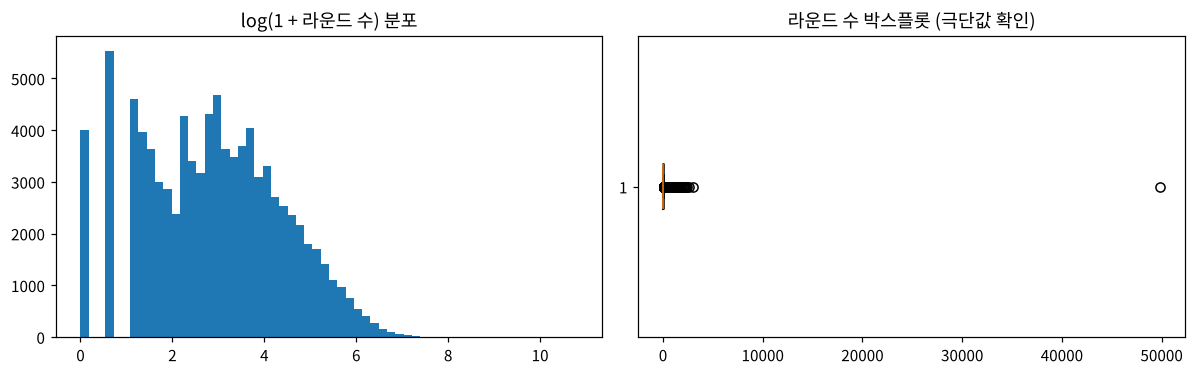

In [5]:
# sum_gamerounds 이상치
print(df["sum_gamerounds"].describe(percentiles=[.5, .9, .99, .999]).round(1))
print("\n상위 5건")
display(df.nlargest(5, "sum_gamerounds"))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(np.log1p(df["sum_gamerounds"]), bins=60)
axes[0].set_title("log(1 + 라운드 수) 분포")
axes[1].boxplot(df["sum_gamerounds"], vert=False)
axes[1].set_title("라운드 수 박스플롯 (극단값 확인)")
plt.tight_layout(); plt.show()

### 이상치 처리 기준
- 14일 = 20,160분이다. 한 라운드가 최소 1~2분이라 가정하면 **10,000라운드 초과는 사실상 불가능**하다(봇, 로그 오류 가능성).
- 이런 극단값은 평균과 일부 검정을 크게 왜곡하므로 **10,000라운드 초과만 제거**하고, 그 외는 실제 유저 행동으로 보고 유지한다.
- 0라운드 유저(설치만 하고 플레이하지 않음)는 정상 행동이라 유지하되, 이후 민감도 분석에서 별도로 확인한다.

In [6]:
OUTLIER_THRESHOLD = 10_000
n_before = len(df)
dfc = df[df["sum_gamerounds"] <= OUTLIER_THRESHOLD].copy()
print(f"제거: {n_before - len(dfc)}건 (전체 {n_before:,} → {len(dfc):,})")

zero_share = dfc.groupby("version")["sum_gamerounds"].apply(lambda s: (s == 0).mean())
print("\n0라운드 유저 비율 (그룹별)\n", zero_share.map("{:.2%}".format), sep="")

제거: 1건 (전체 90,189 → 90,188)

0라운드 유저 비율 (그룹별)
version
gate_30    4.33%
gate_40    4.52%
Name: sum_gamerounds, dtype: str


## 3. A/B 검정

### 3-1. 빈도주의
- **유지율(비율)**: 두 비율 z-검정(2×2 카이제곱 검정과 동일한 결론)과 **부트스트랩 95% 신뢰구간**
- **라운드 수**: 분포가 한쪽으로 크게 치우쳐 있어 평균 비교(t-검정) 대신 **Mann-Whitney U 검정**
- 주 지표 2개이므로 Bonferroni 보정 기준(p < 0.025)으로 판단

In [7]:
A = dfc[dfc["version"] == "gate_30"]
B = dfc[dfc["version"] == "gate_40"]

summary = dfc.groupby("version").agg(
    유저수=("userid", "count"),
    유지율_1일=("retention_1", "mean"),
    유지율_7일=("retention_7", "mean"),
    평균_라운드=("sum_gamerounds", "mean"),
    중앙값_라운드=("sum_gamerounds", "median"),
)
display(summary.round(4))

,유저수,유지율_1일,유지율_7일,평균_라운드,중앙값_라운드
version,,,,,
gate_30,44699,0.4482,0.1902,51.3421,17.0
gate_40,45489,0.4423,0.1820,51.2988,16.0


In [8]:
def prop_result(col, n_boot=2000):
    a, b = A[col].to_numpy(), B[col].to_numpy()
    z, p = proportions_ztest([b.sum(), a.sum()], [len(b), len(a)])
    boots = np.array([RNG.choice(b, len(b)).mean() - RNG.choice(a, len(a)).mean() for _ in range(n_boot)])
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return {"metric": col, "gate_30": a.mean(), "gate_40": b.mean(),
            "diff_pp": (b.mean() - a.mean()) * 100, "ci_lo_pp": lo * 100, "ci_hi_pp": hi * 100,
            "p_value": p, "boots": boots}

freq = [prop_result("retention_1"), prop_result("retention_7")]
freq_df = pd.DataFrame(freq).drop(columns="boots").set_index("metric")
freq_df["유의(p<0.025)"] = freq_df["p_value"] < ALPHA / 2
display(freq_df.round(4))

for r in freq:
    sig = r["p_value"] < ALPHA / 2
    print(f"[{r['metric']}] gate_30 {r['gate_30']:.2%} → gate_40 {r['gate_40']:.2%} "
          f"({r['diff_pp']:+.2f}%p, 95% CI [{r['ci_lo_pp']:+.2f}, {r['ci_hi_pp']:+.2f}], p={r['p_value']:.4f}) "
          f"→ {'통계적으로 유의' if sig else '통계적으로 유의하지 않음'}")

,gate_30,gate_40,diff_pp,ci_lo_pp,ci_hi_pp,p_value,유의(p<0.025)
metric,,,,,,,
retention_1,0.4482,0.4423,-0.5915,-1.2563,0.0483,0.0739,False
retention_7,0.1902,0.1820,-0.8183,-1.3312,-0.3407,0.0016,True


[retention_1] gate_30 44.82% → gate_40 44.23% (-0.59%p, 95% CI [-1.26, +0.05], p=0.0739) → 통계적으로 유의하지 않음
[retention_7] gate_30 19.02% → gate_40 18.20% (-0.82%p, 95% CI [-1.33, -0.34], p=0.0016) → 통계적으로 유의


In [9]:
# 가드레일: 라운드 수 (Mann-Whitney U)
u, p_mw = stats.mannwhitneyu(B["sum_gamerounds"], A["sum_gamerounds"], alternative="two-sided")
prob_sup = u / (len(A) * len(B))
print(f"중앙값  gate_30 {A['sum_gamerounds'].median():.0f} / gate_40 {B['sum_gamerounds'].median():.0f}")
print(f"평균    gate_30 {A['sum_gamerounds'].mean():.2f} / gate_40 {B['sum_gamerounds'].mean():.2f}")
print(f"Mann-Whitney U p-value = {p_mw:.4f}")
print(f"확률 우위(gate_40 유저가 더 많이 플레이할 확률) = {prob_sup:.3f}  (0.5 = 동일)")
print("→ 참여도 차이:", "통계적으로 유의" if p_mw < ALPHA else "유의하지 않음")

중앙값  gate_30 17 / gate_40 16
평균    gate_30 51.34 / gate_40 51.30
Mann-Whitney U p-value = 0.0509
확률 우위(gate_40 유저가 더 많이 플레이할 확률) = 0.496  (0.5 = 동일)
→ 참여도 차이: 유의하지 않음


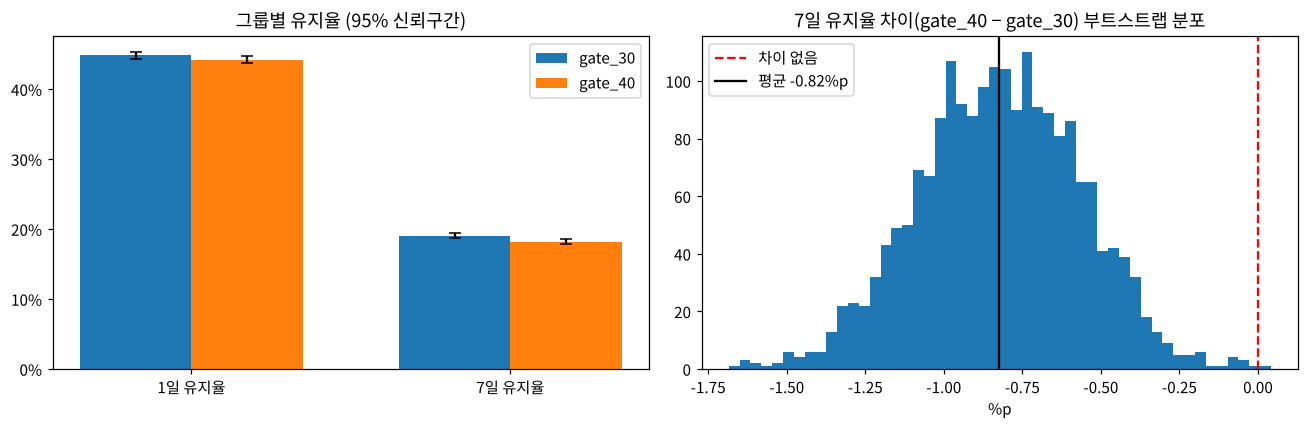

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# (1) 유지율 비교 (Wilson 95% CI)
metrics = ["retention_1", "retention_7"]
x = np.arange(len(metrics)); w = 0.35
for i, (g, d) in enumerate([("gate_30", A), ("gate_40", B)]):
    vals = np.array([d[m].mean() for m in metrics])
    lo = np.array([proportion_confint(d[m].sum(), len(d), method="wilson")[0] for m in metrics])
    hi = np.array([proportion_confint(d[m].sum(), len(d), method="wilson")[1] for m in metrics])
    axes[0].bar(x + (i - 0.5) * w, vals, w, yerr=[vals - lo, hi - vals], capsize=4, label=g)
axes[0].set_xticks(x); axes[0].set_xticklabels(["1일 유지율", "7일 유지율"])
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].set_title("그룹별 유지율 (95% 신뢰구간)"); axes[0].legend()

# (2) 7일 유지율 차이의 부트스트랩 분포
d7 = freq[1]["boots"] * 100
axes[1].hist(d7, bins=50)
axes[1].axvline(0, color="red", linestyle="--", label="차이 없음")
axes[1].axvline(d7.mean(), color="black", label=f"평균 {d7.mean():+.2f}%p")
axes[1].set_title("7일 유지율 차이(gate_40 − gate_30) 부트스트랩 분포")
axes[1].set_xlabel("%p"); axes[1].legend()
plt.tight_layout(); plt.show()

### 3-2. 베이지안
- 유지율은 성공/실패 데이터이므로 **Beta-Binomial** 모델을 쓴다. 사전분포는 정보가 없다고 보고 Beta(1, 1).
- 사후분포에서 샘플링해 **P(gate_40이 더 높을 확률)**, **기대 손실**(잘못 선택했을 때 평균적으로 잃는 유지율), 차이의 **95% 신용구간**을 구한다.
- p-value는 "차이가 없다는 가정 하에 이런 데이터가 나올 확률"이라 해석이 어렵다. 베이지안 결과는 "gate_40이 더 낫다/나쁘다는 확률"로 바로 말할 수 있어 비즈니스 의사결정에 쓰기 쉽다.

,P(gate_40 > gate_30),기대손실: gate_40 선택(%p),기대손실: gate_30 선택(%p),신용구간 하한(%p),신용구간 상한(%p)
retention_1,0.0367,0.5972,0.0048,-1.2422,0.0567
retention_7,0.0009,0.8179,0.0001,-1.3256,-0.3120


[retention_1] gate_40이 더 높을 확률 3.7%, 차이 95% 신용구간 [-1.24, +0.06]%p
[retention_7] gate_40이 더 높을 확률 0.1%, 차이 95% 신용구간 [-1.33, -0.31]%p


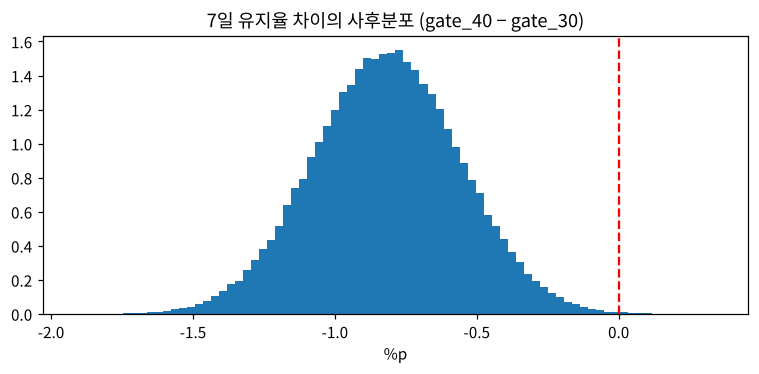

In [11]:
def bayes(col, n=200_000):
    a, b = A[col], B[col]
    post_a = RNG.beta(1 + a.sum(), 1 + len(a) - a.sum(), n)
    post_b = RNG.beta(1 + b.sum(), 1 + len(b) - b.sum(), n)
    diff = post_b - post_a
    return {"p_b_better": (diff > 0).mean(),
            "exp_loss_choose_b": np.maximum(-diff, 0).mean() * 100,   # gate_40을 골랐는데 틀렸을 때 평균 손실(%p)
            "exp_loss_choose_a": np.maximum(diff, 0).mean() * 100,    # gate_30을 골랐는데 틀렸을 때 평균 손실(%p)
            "ci_lo_pp": np.percentile(diff, 2.5) * 100, "ci_hi_pp": np.percentile(diff, 97.5) * 100,
            "diff": diff}

bayes_res = {m: bayes(m) for m in ["retention_1", "retention_7"]}
bayes_df = pd.DataFrame({m: {k: v for k, v in r.items() if k != "diff"} for m, r in bayes_res.items()}).T
bayes_df.columns = ["P(gate_40 > gate_30)", "기대손실: gate_40 선택(%p)", "기대손실: gate_30 선택(%p)", "신용구간 하한(%p)", "신용구간 상한(%p)"]
display(bayes_df.round(4))

for m, r in bayes_res.items():
    print(f"[{m}] gate_40이 더 높을 확률 {r['p_b_better']:.1%}, 차이 95% 신용구간 [{r['ci_lo_pp']:+.2f}, {r['ci_hi_pp']:+.2f}]%p")

plt.figure(figsize=(7, 3.5))
plt.hist(bayes_res["retention_7"]["diff"] * 100, bins=80, density=True)
plt.axvline(0, color="red", linestyle="--")
plt.title("7일 유지율 차이의 사후분포 (gate_40 − gate_30)"); plt.xlabel("%p")
plt.tight_layout(); plt.show()

### 검정 결과 해석 포인트
- 두 방법(빈도주의, 베이지안)의 결론이 같은 방향이면 결과의 신뢰도가 올라간다.
- **통계적 유의성 ≠ 비즈니스 유의성**: 표본이 크면 아주 작은 차이도 유의하게 나온다. 차이의 크기(%p)와 신뢰구간으로 실질적 영향을 함께 본다.
- 1일 유지율은 게이트(30·40레벨)를 만나기 전에 측정되는 경우가 많아, 효과가 7일 유지율에서 더 뚜렷할 수 있다. 다음 섹션에서 이를 확인한다.

## 4. 세그먼트 Deep Dive
**핵심 아이디어**: 게이트는 레벨 30(또는 40)에 도달한 유저에게만 보인다.
- `sum_gamerounds`는 레벨 수가 아니라 **플레이한 판 수**다. 실패하거나 다시 한 판도 모두 포함된다.
- 레벨 30에 가려면 최소 30판은 해야 하므로, 라운드 수가 30 미만인 유저는 **어느 쪽 게이트도 만나지 않았다** → 이 구간에서는 두 그룹의 차이가 없어야 한다. (게이트 전 구간 점검)
- 라운드 수가 30 이상이어도 실제로 몇 레벨까지 갔는지는 알 수 없다. 30라운드 이상 구간은 **게이트를 만났을 가능성이 있는 유저**로 보고, 플레이량 구간별로 7일 유지율을 비교한다.

> 주의: 라운드 수는 실험 처치(게이트 위치)의 영향을 받는 **처치 후 변수**다. 구간별 결과는 인과 효과의 확정이 아니라 **효과가 어떤 플레이량 구간에서 나타나는지 탐색**하는 용도로 해석한다.

In [12]:
labels = ["0 (미플레이)", "1~29 (게이트 전)", "30~39", "40~99", "100+"]
dfc["segment"] = pd.cut(dfc["sum_gamerounds"], bins=[-1, 0, 29, 39, 99, np.inf], labels=labels)

def seg_table(metric):
    rows = []
    for seg in labels:
        s = dfc[dfc["segment"] == seg]
        a = s[s["version"] == "gate_30"][metric]; b = s[s["version"] == "gate_40"][metric]
        try:
            _, p = proportions_ztest([b.sum(), a.sum()], [len(b), len(a)])
        except Exception:
            p = np.nan
        rows.append({"구간": seg, "gate_30 인원": len(a), "gate_40 인원": len(b),
                     "gate_30": a.mean(), "gate_40": b.mean(),
                     "차이(%p)": (b.mean() - a.mean()) * 100, "p-value": p,
                     "p-value(Bonferroni)": min(p * len(labels), 1) if pd.notna(p) else np.nan})
    return pd.DataFrame(rows).set_index("구간")

seg7 = seg_table("retention_7")
seg1 = seg_table("retention_1")
print("7일 유지율 구간별 비교"); display(seg7.round(4))
print("1일 유지율 구간별 비교"); display(seg1.round(4))

7일 유지율 구간별 비교


,gate_30 인원,gate_40 인원,gate_30,gate_40,차이(%p),p-value,p-value(Bonferroni)
구간,,,,,,,
0 (미플레이),1937,2057,0.0083,0.0063,-0.1940,0.4704,1.0000
1~29 (게이트 전),26107,26819,0.0451,0.0418,-0.3286,0.0638,0.3189
30~39,3090,2786,0.1573,0.1569,-0.0426,0.9643,1.0000
40~99,7398,7479,0.3290,0.2939,-3.5118,0.0000,0.0000
100+,6167,6348,0.7114,0.7103,-0.1064,0.8955,1.0000


1일 유지율 구간별 비교


,gate_30 인원,gate_40 인원,gate_30,gate_40,차이(%p),p-value,p-value(Bonferroni)
구간,,,,,,,
0 (미플레이),1937,2057,0.0212,0.0224,0.1196,0.7958,1.000
1~29 (게이트 전),26107,26819,0.2548,0.2518,-0.3036,0.4220,1.000
30~39,3090,2786,0.6401,0.6612,2.1034,0.0914,0.457
40~99,7398,7479,0.7839,0.7724,-1.1431,0.0934,0.467
100+,6167,6348,0.9022,0.8982,-0.3986,0.4570,1.000


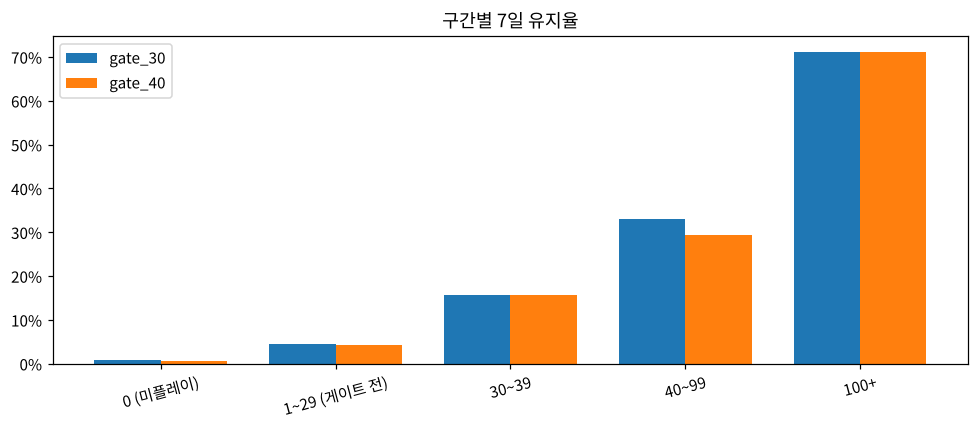

보정 후 유의한 구간: ['40~99']
게이트 전 구간 점검(0, 1~29라운드) 차이: 없음 (정상)


In [13]:
x = np.arange(len(labels)); w = 0.38
plt.figure(figsize=(9, 4))
plt.bar(x - w / 2, seg7["gate_30"], w, label="gate_30")
plt.bar(x + w / 2, seg7["gate_40"], w, label="gate_40")
plt.xticks(x, labels, rotation=15)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.title("구간별 7일 유지율"); plt.legend(); plt.tight_layout(); plt.show()

sig_segs = seg7.index[seg7["p-value(Bonferroni)"] < ALPHA].tolist()
pre_gate = seg7.loc[["0 (미플레이)", "1~29 (게이트 전)"], "p-value(Bonferroni)"]
print("보정 후 유의한 구간:", sig_segs if sig_segs else "없음")
print("게이트 전 구간 점검(0, 1~29라운드) 차이:", "없음 (정상)" if (pre_gate >= ALPHA).all() else "있음 → 그룹 간 사전 차이 가능성 점검 필요")

In [14]:
# 민감도 분석: 결과가 특정 유저군에 좌우되지 않는지
def quick(sub, name):
    a = sub[sub["version"] == "gate_30"]["retention_7"]; b = sub[sub["version"] == "gate_40"]["retention_7"]
    _, p = proportions_ztest([b.sum(), a.sum()], [len(b), len(a)])
    return {"분석 대상": name, "인원": len(sub), "gate_30": a.mean(), "gate_40": b.mean(), "차이(%p)": (b.mean() - a.mean()) * 100, "p-value": p}

sens = pd.DataFrame([
    quick(dfc, "전체 (기준)"),
    quick(dfc[dfc["sum_gamerounds"] > 0], "0라운드 유저 제외"),
    quick(dfc[dfc["sum_gamerounds"] >= 30], "30라운드 이상 (게이트 경험 가능 유저)"),
]).set_index("분석 대상")
display(sens.round(4))

,인원,gate_30,gate_40,차이(%p),p-value
분석 대상,,,,,
전체 (기준),90188,0.1902,0.1820,-0.8183,0.0016
0라운드 유저 제외,86194,0.1984,0.1903,-0.8103,0.0026
30라운드 이상 (게이트 경험 가능 유저),33268,0.4387,0.4300,-0.8702,0.1093


### 4장 결과 해석 (실제 데이터 실행 결과 기준)
- 게이트 전 구간(0, 1~29라운드)은 차이가 없어 **두 그룹이 게이트를 만나기 전까지는 비슷했다**는 점을 확인했다. 30~39, 100+ 구간도 차이가 거의 없다.
- 차이는 **40~99라운드 구간에 집중**된다. gate_30 32.9% vs gate_40 29.4% (−3.5%p), Bonferroni 보정 후에도 유의하다.
- 100+ 라운드 유저는 게이트 위치와 무관하게 유지율이 같다. 게이트 위치에 영향을 받지 않는 핵심 유저층이다.
- 다만 라운드 수는 레벨 수가 아니라서, 40~99라운드 유저가 실제로 몇 레벨에서 게이트를 만났는지는 이 데이터로 확인할 수 없다. 또 라운드 수 자체가 처치의 영향을 받아 두 그룹의 구간 구성이 다를 수 있다. 이 결과는 **효과가 중간 플레이량 유저에게서 나타난다는 탐색적 근거**로만 사용한다.
- 30라운드 이상 유저만 보면 차이(−0.87%p)가 유의하지 않다(p≈0.11). 표본이 줄어 검정력이 낮아진 영향도 있어, 전체 결과와 방향은 같다.

## 5. 결론과 액션 아이템
아래 셀은 위 분석 결과를 읽어 **결론을 자동으로 정리**한다. (재실행하면 결과에 맞게 문구가 갱신됨)

In [15]:
r1, r7 = freq
b7 = bayes_res["retention_7"]
sig7 = r7["p_value"] < ALPHA / 2
sig1 = r1["p_value"] < ALPHA / 2
fp = lambda p: "p<0.0001" if p < 1e-4 else f"p={p:.4f}"

if sig7 and r7["diff_pp"] < 0:
    decision = "gate_30 유지 (gate_40 도입 비권장)"
elif sig7 and r7["diff_pp"] > 0:
    decision = "gate_40 도입 권장"
else:
    decision = "7일 유지율 차이를 확인하지 못함 → 도입 보류, 추가 검증 필요"

worst_seg = seg7.loc[seg7.index[2:], "차이(%p)"].idxmin()
best_seg = seg7.loc[seg7.index[2:], "차이(%p)"].idxmax()

print("=" * 64)
print(f"의사결정: {decision}")
print("=" * 64)
print("\n[근거]")
print(f"1) 7일 유지율: gate_30 {r7['gate_30']:.2%} → gate_40 {r7['gate_40']:.2%} ({r7['diff_pp']:+.2f}%p), "
      f"{fp(r7['p_value'])} → {'유의' if sig7 else '유의하지 않음'} (보정 기준 0.025)")
print(f"2) 1일 유지율: {r1['gate_30']:.2%} → {r1['gate_40']:.2%} ({r1['diff_pp']:+.2f}%p), "
      f"{fp(r1['p_value'])} → {'유의' if sig1 else '유의하지 않음'}")
print(f"3) 베이지안: gate_40이 더 높을 확률 {b7['p_b_better']:.1%}, 차이 95% 신용구간 [{b7['ci_lo_pp']:+.2f}, {b7['ci_hi_pp']:+.2f}]%p")
print(f"4) 구간별: 30라운드 이상 구간 중 gate_40이 가장 불리한 구간은 '{worst_seg}' ({seg7.loc[worst_seg, '차이(%p)']:+.2f}%p), "
      f"가장 유리(또는 덜 불리)한 구간은 '{best_seg}' ({seg7.loc[best_seg, '차이(%p)']:+.2f}%p)")

print("\n[액션 아이템]")
if sig7 and r7["diff_pp"] < 0:
    print("1. gate_40 전면 적용을 보류하고 gate_30을 유지한다.")
    print(f"2. 감소 폭이 큰 '{worst_seg}' 구간 유저의 이탈 원인을 분석한다. (레벨 도달·대기 시간·결제 시도 로그가 확보되면 함께 확인)")
    print("3. 게이트 위치를 옮기는 대신 게이트 보상/대기 시간 같은 다른 변수를 실험한다.")
elif sig7 and r7["diff_pp"] > 0:
    print("1. gate_40을 단계적으로 확대 적용하고 유지율과 매출 지표를 함께 모니터링한다.")
    print(f"2. 개선 폭이 큰 '{best_seg}' 구간의 특성을 파악해 다른 게이트 설계에 응용한다.")
    print("3. 매출 지표(결제 전환, ARPU)를 확인한 뒤 최종 확정한다.")
else:
    print("1. 현 시점에는 게이트 위치 변경의 효과를 입증할 근거가 부족하므로 변경을 보류한다.")
    print("2. 표본 확대 또는 기간 연장 후 재검정한다. (현재 탐지 가능한 최소 차이는 약 %.2f%%p)" % (mde_actual * 100))
    print("3. 유지율 개선이 목표라면 초반 온보딩/보상 개선을 별도 실험 후보로 올린다.")
print("4. 레벨 도달 로그(게이트를 만난 시점)와 1~3일 차 일자별 로그를 확보해, 게이트를 만난 직후의 이탈을 직접 확인한다.")

의사결정: gate_30 유지 (gate_40 도입 비권장)

[근거]
1) 7일 유지율: gate_30 19.02% → gate_40 18.20% (-0.82%p), p=0.0016 → 유의 (보정 기준 0.025)
2) 1일 유지율: 44.82% → 44.23% (-0.59%p), p=0.0739 → 유의하지 않음
3) 베이지안: gate_40이 더 높을 확률 0.1%, 차이 95% 신용구간 [-1.33, -0.31]%p
4) 구간별: 30라운드 이상 구간 중 gate_40이 가장 불리한 구간은 '40~99' (-3.51%p), 가장 유리(또는 덜 불리)한 구간은 '30~39' (-0.04%p)

[액션 아이템]
1. gate_40 전면 적용을 보류하고 gate_30을 유지한다.
2. 감소 폭이 큰 '40~99' 구간 유저의 이탈 원인을 분석한다. (레벨 도달·대기 시간·결제 시도 로그가 확보되면 함께 확인)
3. 게이트 위치를 옮기는 대신 게이트 보상/대기 시간 같은 다른 변수를 실험한다.
4. 레벨 도달 로그(게이트를 만난 시점)와 1~3일 차 일자별 로그를 확보해, 게이트를 만난 직후의 이탈을 직접 확인한다.


### 한계점
- **매출 지표 부재**: 게이트는 결제 유도 장치인데 결제/ARPU 데이터가 없어 수익 영향은 평가하지 못했다. 유지율이 올라도 매출이 줄 수 있어, 실제 의사결정에는 매출 지표 확인이 필요하다.
- **관측 기간**: 7일 유지율까지만 있어 장기(30일 이상) 효과와 LTV는 알 수 없다. 신기 효과(novelty effect)로 초기 결과가 장기와 다를 수 있다.
- **그룹 비율**: 그룹 인원 비율이 완전한 50:50이 아니다(SRM 점검 결과 참고). 배정 로직 확인이 필요하다.
- **처치 후 변수 분석**: 라운드 수 기반 세그먼트는 처치의 영향을 받은 변수를 쓰므로 인과 해석에 한계가 있다.
- **라운드 수 ≠ 레벨**: 데이터에 레벨 도달 정보가 없어, 유저가 실제로 게이트를 만났는지는 직접 확인할 수 없다.
- **변수 부족**: 플랫폼, 국가, 유입 경로, 결제 이력 같은 유저 속성이 없어 세그먼트 분석이 단순하다.
- **다중 비교**: 구간별 분석은 탐색적이며, Bonferroni 보정을 적용해도 사전에 정한 가설 검정은 아니다.

### 다음 실험 제안
1. **결제/매출 가드레일 추가**: 유지율과 ARPU를 함께 보는 실험 설계
2. **게이트 위치 다변량 실험**: 30 / 35 / 40 / 50 등 여러 안을 동시에 비교하고, 순차 검정(sequential testing)으로 조기 종료 기준 설정
3. **게이트 형태 실험**: 위치 대신 대기 시간, 보상, 광고 시청 대체 옵션 등을 변경
4. **온보딩 개선 실험**: 이탈 위험이 가장 큰 초기 1~3일 경험 개선